# Wireless Networking and Mobile Computing

### Prerequisites

This Jupyter Notebook has been tested with Visual Studio Code, running in a local Python environment.

**Installs**

In [1]:
# --- Installs: ensure required packages are available ---
%pip install numpy scipy soundfile matplotlib imageio-ffmpeg --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**Imports**

In [2]:
# --- Imports: libraries used in this notebook ---
import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

**Declarations**

Set the variables below and run the generation cell. 

- `INPUT_FILE` is the path to the audio file that we will embed data into.

In [3]:
# --- Declarations: editable variables for students ---
INPUT_FILE = "Audio/CrabRave.wav"

### 3. Embedding Data into Audio
Embedding data alters certain properties of an audio signal to carry hidden or auxiliary information. Digital watermarking and steganography techniques (like LSB, Phase Modulation, or Spread Spectrum) encode bits by subtly changing these parameters, creating a minimal perceptual distortion while embedding recoverable data.

The following embedding techniques are basic and unprotected. While recovery works on the original embedded audio, it already deteriorates noticeably with even small amounts of noise as you will see in this notebook. It is not applicable to real-world usage and breaks down with compression or transmission over the air. 

In [4]:
# --- Helpers ---
import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

FS_TARGET = 16000
BIT_RATE = 16
TB = 1 / BIT_RATE

# Normalize audio
def normalize(y):
    return y / (np.max(np.abs(y)) + 1e-9)

# Load audio
x, fs = sf.read(INPUT_FILE)
if x.ndim > 1:
    x = x[:, 0]
x = normalize(x)
if fs != FS_TARGET:
    x = resample_poly(x, FS_TARGET, fs)
    fs = FS_TARGET
print(f"Audio loaded: {len(x)} samples @ {fs} Hz")

# Generate random bits
Ns = int(fs * TB)
Nbits = 2**19
bits = np.random.randint(0, 2, Nbits, dtype=np.uint8)
print(f"Generated {Nbits} random bits for testing.")

# Bit-Error Rate calculation
def bit_error_rate(ref, rec):
    return np.mean(ref != rec)

# Add noise to audio
def add_noise(file, noise_level=0.01, out_file=None):
    audio, fs = sf.read(file)
    if audio.ndim > 1:
        audio = audio[:, 0]  # mono
    audio = audio.astype(np.float32)
    noise = np.random.randn(len(audio)) * noise_level
    noisy = audio + noise
    noisy /= np.max(np.abs(noisy)) + 1e-12
    out_file = out_file or file.replace(".wav", "_noisy.wav")
    sf.write(out_file, noisy, fs)
    return out_file

Audio loaded: 983516 samples @ 16000 Hz
Generated 524288 random bits for testing.


---
#### 3.1 LSB Encoding
##### Encoding

**Logic:** replace the least significant bit (LSB) of each 16-bit PCM sample with the corresponding message bit.

**Math:**  Each sample’s least significant bit is replaced with the message bit:

$$
x'_i = x_i - (x_i \bmod 2) + b_i,
$$

We clear the old last bit and insert the new one.


In [5]:
# --- LSB Encoding ---
def lsb_encode(x, bits, fs, out_file="CrabRave_LSB.wav", seed=0):
    """Embed bits randomly across the whole waveform using LSB."""
    x_int16 = np.int16(x / np.max(np.abs(x)) * 32767)
    flat = x_int16.reshape(-1)
    n = min(len(bits), len(flat))

    np.random.seed(seed)
    idx = np.random.choice(len(flat), n, replace=False)

    flat_uint = flat.astype(np.uint16)
    flat_uint[idx] = (flat_uint[idx] & 0xFFFE) | bits[:n]
    flat = flat_uint.view(np.int16)

    y = flat.reshape(x_int16.shape)
    sf.write(out_file, y, fs, subtype='PCM_16')
    print(f"Saved {out_file} ({n} bits embedded)")

lsb_encode(x, bits, fs)

Saved CrabRave_LSB.wav (524288 bits embedded)


##### Decoding
Recover bits by reading the LSB of each integer sample:
$$
\hat{b}_i = x'_i \bmod 2.
$$

In [6]:
# --- LSB Decoding ---
def lsb_decode(file, Nbits, seed=0):
    """Recover bits from randomized LSB positions."""
    y_int16, _ = sf.read(file, dtype='int16')
    flat = y_int16.reshape(-1)
    np.random.seed(seed)
    idx = np.random.choice(len(flat), Nbits, replace=False)
    return (flat[idx] & 1).astype(np.uint8)

# Original decode
rec_bits = lsb_decode("CrabRave_LSB.wav", len(bits))
ber_clean = bit_error_rate(bits, rec_bits)
print(f"LSB clean: BER = {ber_clean:.4f} ({np.sum(rec_bits != bits)} errors / {len(bits)})")

# Noisy decode
noisy_file = add_noise("CrabRave_LSB.wav", noise_level=0.01)
rec_bits_noisy = lsb_decode(noisy_file, len(bits))
ber_noisy = bit_error_rate(bits, rec_bits_noisy)
print(f"LSB noisy: BER = {ber_noisy:.4f} ({np.sum(rec_bits_noisy != bits)} errors / {len(bits)})")

LSB clean: BER = 0.0000 (0 errors / 524288)
LSB noisy: BER = 0.5008 (262552 errors / 524288)


---
#### 3.2 Phase Modulation (PM)
##### Encoding

**Logic:** embed message bits in the *phase* of selected FFT frequency components while keeping magnitudes unchanged. This preserves the audio’s perceptual quality since only phase is altered.

**Math:**  
For each segment of the signal, compute the FFT:

$$
X[k] = |X[k]| e^{j\phi[k]}.
$$

Then set the phase of selected bins according to the bit value:

$$
\phi'[k_i] =
\begin{cases}
+\pi/2, & b_i = 1 \\
-\pi/2, & b_i = 0
\end{cases}
$$

After embedding, reconstruct the time-domain signal:

$$
x'(n) = \mathrm{Re}\!\left\{\mathrm{IFFT}\!\big(|X[k]| e^{j\phi'[k]}\big)\right\}.
$$

In [7]:
# --- PM Encoding ---
def pm_encode(in_file, bits, out_file="CrabRave_PM.wav", bins_per_seg=64):
    """Embed bits using original PM logic, distributed across the full file."""
    audio, fs = sf.read(in_file)
    if audio.ndim > 1:
        audio = audio[:, 0]
    audio = audio.astype(np.float32) / np.max(np.abs(audio))

    seg_len = 4096
    seg_mid = seg_len // 2
    seg_num = int(np.ceil(len(audio) / seg_len))
    audio = np.pad(audio, (0, seg_num * seg_len - len(audio)))
    segs = audio.reshape(seg_num, seg_len)

    segs_f = np.fft.fft(segs)
    mag = np.abs(segs_f)
    phase = np.angle(segs_f)

    bits_per_seg = min(bins_per_seg, max(1, len(bits)//seg_num))
    bit_idx = 0

    for i in range(seg_num):
        if bit_idx >= len(bits):
            break
        chunk = bits[bit_idx:bit_idx + bits_per_seg]
        msg_phase = np.where(chunk == 1, np.pi/4, -np.pi/4)  # smaller shift = subtler
        phase[i, seg_mid - len(chunk):seg_mid] = msg_phase
        phase[i, seg_mid + 1:seg_mid + 1 + len(chunk)] = -msg_phase[::-1]
        bit_idx += bits_per_seg

    encoded = np.fft.ifft(mag * np.exp(1j * phase)).real.reshape(-1)
    encoded = encoded / np.max(np.abs(encoded))
    sf.write(out_file, encoded, fs)
    print(f"Saved {out_file} ({bit_idx} bits embedded)")
    return bit_idx  # return how many bits we embedded

pm_length =pm_encode(INPUT_FILE, bits)

Saved CrabRave_PM.wav (15424 bits embedded)


##### Decoding
Recover bits by taking the FFT of the encoded signal and checking the phase sign. This requires knowledge of the bit segment length that was used for encoding and which frequency bins carry the data:

$$
\hat{b}_i =
\begin{cases}
1, & \phi[k_i] > 0 \\
0, & \phi[k_i] < 0
\end{cases}.
$$

In [8]:
# --- PM Decoding ---
def pm_decode(file, Nbits, bins_per_seg=64, seg_len=4096):
    """Decode PM bits distributed across the full file."""
    audio, fs = sf.read(file)
    if audio.ndim > 1:
        audio = audio[:, 0]
    audio = audio.astype(np.float32) / np.max(np.abs(audio))

    seg_mid = seg_len // 2
    seg_num = int(np.ceil(len(audio) / seg_len))
    audio = np.pad(audio, (0, seg_num * seg_len - len(audio)))
    segs = audio.reshape(seg_num, seg_len)

    rec_bits = []
    for seg in segs:
        phase = np.angle(np.fft.fft(seg))
        chunk = (phase[seg_mid - bins_per_seg:seg_mid] > 0).astype(np.uint8)
        rec_bits.extend(chunk)
        if len(rec_bits) >= Nbits:
            break
    return np.array(rec_bits[:Nbits], dtype=np.uint8)

# Original decode
rec_bits = pm_decode("CrabRave_PM.wav", pm_length)
ber_clean = bit_error_rate(bits[:pm_length], rec_bits)
print(f"PM clean: BER = {ber_clean:.4f} ({np.sum(rec_bits != bits[:pm_length])} errors / {pm_length})")

# Noisy decode
noisy_file = add_noise("CrabRave_PM.wav", noise_level=0.01)
rec_bits_noisy = pm_decode(noisy_file, pm_length)
ber_noisy = bit_error_rate(bits[:pm_length], rec_bits_noisy)
print(f"PM noisy: BER = {ber_noisy:.4f} ({np.sum(rec_bits_noisy != bits[:pm_length])} errors / {pm_length})")



PM clean: BER = 0.0000 (0 errors / 15424)
PM noisy: BER = 0.3815 (5885 errors / 15424)


---
#### 3.3 Spread Spectrum Noise (SSN)
##### Encoding

**Logic:** each bit is represented by a pseudo-random noise sequence (“chip”) that is added or subtracted from the carrier. The energy of the message is spread across a wide frequency range, making it robust and difficult to detect.

**Math:**  Let $c_i[n]$ be a pseudo-random ±1 sequence for bit $i$, and $g$ a small embedding gain. The encoded signal is:

$$
s[n] = x[n] + g \sum_i (2b_i - 1)c_i[n].
$$

When $b_i = 1$, the chip is added; when $b_i = 0$, it is subtracted.


In [9]:
# --- SSN Encoding ---
def ssn_encode(x, bits, gain=0.0125, density=0.01, out_file="CrabRave_SSN.wav"):
    N = len(x)
    max_bits = len(bits)
    usable_bits = int(max_bits * density)
    chip_len = N // usable_bits

    noise = np.zeros(N)
    np.random.seed(0)
    for i in range(usable_bits):
        chip = np.random.randn(chip_len)
        chip *= (1 if bits[i] == 1 else -1)
        start, end = i * chip_len, (i + 1) * chip_len
        noise[start:end] = chip

    y = normalize(x + gain * noise)
    sf.write(out_file, y, FS_TARGET)
    print(f"Saved {out_file} ({usable_bits} bits embedded, density={density:.2f})")
    return usable_bits

ssn_length = ssn_encode(x, bits)

Saved CrabRave_SSN.wav (5242 bits embedded, density=0.01)


##### Decoding
Recreate the same noise chips $c_i[n]$ using the same random seed and compute their correlation with the received signal:

$$
r_i = \sum_n s[n] \, c_i[n].
$$

The recovered bit is then determined by the sign of the correlation:

$$
\hat{b}_i =
\begin{cases}
1, & r_i > 0 \\
0, & r_i < 0
\end{cases}.
$$

In [10]:
# --- SSN Decoding ---
def ssn_decode(y, bits_len):
    N = len(y)
    chip_len = N // bits_len
    rec_bits = []
    np.random.seed(0)
    for i in range(bits_len):
        chip = np.random.randn(chip_len)
        s = np.sum(y[i * chip_len:(i + 1) * chip_len] * chip)
        rec_bits.append(1 if s > 0 else 0)
    return np.array(rec_bits, dtype=np.uint8)

y, _ = sf.read("CrabRave_SSN.wav")
if y.ndim > 1:
    y = y[:, 0]

# Original decode
rec_bits = ssn_decode(y, ssn_length)
ber_clean = bit_error_rate(bits[:ssn_length], rec_bits)
print(f"SSN clean: BER = {ber_clean:.4f} ({np.sum(rec_bits != bits[:ssn_length])} errors / {ssn_length})")

# Noisy decode
noisy_file = add_noise("CrabRave_SSN.wav", noise_level=0.01)
y_noisy, _ = sf.read(noisy_file)
if y_noisy.ndim > 1:
    y_noisy = y_noisy[:, 0]
rec_bits_noisy = ssn_decode(y_noisy, ssn_length)
ber_noisy = bit_error_rate(bits[:ssn_length], rec_bits_noisy)
print(f"SSN noisy: BER = {ber_noisy:.4f} ({np.sum(rec_bits_noisy != bits[:ssn_length])} errors / {ssn_length})")

SSN clean: BER = 0.2144 (1124 errors / 5242)
SSN noisy: BER = 0.2133 (1118 errors / 5242)


---
#### 3.4 Blind Listening Test
"Can you hear a difference?" is easy to answer wrongly in both directions: knowing which file is encoded makes you hear differences that are not there, and missing a difference you were not listening for. A **blind ABX test** removes the guessing about your own guessing.

Each trial plays the same 5 s excerpt three times: **A** is the original, **B** is the encoded version, and **X** is secretly one of the two. You say whether X is A or B. Excerpts are matched in loudness, so volume gives nothing away.

With 10 trials, pure guessing scores about 5/10. A score of **9 or 10 out of 10** is very unlikely by chance (about 1%), so only then can you claim to hear the difference. Use headphones if you have them.

In [15]:
# INPUT
METHOD_FILES = {"LSB": "CrabRave_LSB.wav", "PM": "CrabRave_PM.wav", "SSN": "CrabRave_SSN.wav"}
METHOD = "SSN"        # <-- Change this. Run the test once for each method
TRIALS = 10

import random
from IPython.display import Audio, display, clear_output

def _excerpt(y, fs, start, seconds):
    seg = y[int(start * fs): int((start + seconds) * fs)]
    return seg / (np.sqrt(np.mean(seg ** 2)) + 1e-12) * 0.1            # equal loudness

def listening_test(original, encoded, trials=10, seconds=5):
    a, fa = sf.read(original); b, fb = sf.read(encoded)
    a = a if a.ndim == 1 else a[:, 0]; b = b if b.ndim == 1 else b[:, 0]
    assert fa == fb, "sample rates differ"
    length = min(len(a), len(b)) / fa
    correct = 0
    for k in range(trials):
        start = random.uniform(0, length - seconds)
        x_is_a = random.random() < 0.5
        A, B = _excerpt(a, fa, start, seconds), _excerpt(b, fb, start, seconds)
        clear_output(wait=True)
        print(f"Trial {k + 1}/{trials}   (score so far: {correct}/{k})")
        for name, sig in (("A (original)", A), ("B (encoded)", B), ("X (A or B?)", A if x_is_a else B)):
            print(name); display(Audio(sig, rate=fa, normalize=False))
        answer = input("Is X the same as A or B? [a/b] ").strip().lower()
        correct += (answer == "a") == x_is_a
    clear_output(wait=True)
    print(f"{METHOD}: {correct}/{trials} correct")
    return correct

score = listening_test(INPUT_FILE, METHOD_FILES[METHOD], TRIALS)

SSN: 10/10 correct


---
#### 3.5 Channel Attacks
The decodes above used a fixed, small amount of noise. Here each encoded file goes through three kinds of damage that a real channel causes, and the decoders from 3.1 to 3.3 try to read it back:

- **Noise** at a chosen **signal-to-noise ratio (SNR)**: 40 dB is a quiet room close to the speaker, 0 dB means the noise is as strong as the music.
- **MP3 compression** at 128 kbit/s: what happens when the file is shared online.
- **Echo**: the sound arrives once directly and then again and again from the walls (a room with a reverberation time of 0.3 s). No noise at all is added here.

A bit error rate of 0.5 means the decoder is guessing. MP3 needs ffmpeg (installed with `imageio-ffmpeg`); without it, that row is skipped.

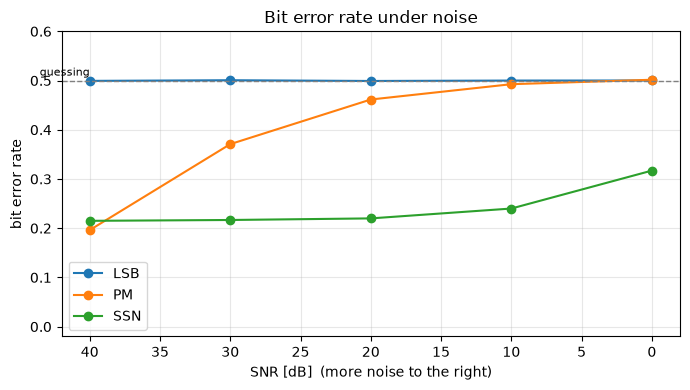

method      40 dB    30 dB    20 dB    10 dB     0 dB  MP3 128k    echo
LSB         0.499    0.501    0.499    0.500    0.500     0.500   0.501
PM          0.196    0.371    0.461    0.493    0.502     0.505   0.203
SSN         0.215    0.217    0.220    0.240    0.317     0.233   0.260


In [12]:
import subprocess, shutil, tempfile, os
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

def _read_mono(file):
    y, fs = sf.read(file)
    return (y if y.ndim == 1 else y[:, 0]), fs

def _write(file, y, fs):
    sf.write(file, np.clip(y, -1, 1), fs, subtype="PCM_16")   # 16-bit, like a real recording
    return file

def attack_noise(file, snr_db, out, seed=0):
    y, fs = _read_mono(file)
    noise_power = np.mean(y ** 2) / 10 ** (snr_db / 10)
    return _write(out, y + np.random.default_rng(seed).normal(0, np.sqrt(noise_power), len(y)), fs)

def attack_echo(file, out, rt60=0.3, seed=0):
    y, fs = _read_mono(file)
    t = np.arange(int(rt60 * fs)) / fs
    h = np.random.default_rng(seed).standard_normal(len(t)) * np.exp(-6.91 * t / rt60) * 0.05
    h[:int(0.003 * fs)] = 0; h[0] = 1.0                       # direct sound, then the room
    wet = fftconvolve(y, h)[:len(y)]
    return _write(out, wet / np.max(np.abs(wet)) * np.max(np.abs(y)), fs)

def _ffmpeg():
    exe = shutil.which("ffmpeg")
    if exe: return exe
    try:
        import imageio_ffmpeg; return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None

def attack_mp3(file, out, kbps=128):
    ff = _ffmpeg()
    if ff is None: return None
    _, fs = _read_mono(file)
    with tempfile.TemporaryDirectory() as d:
        mp3 = os.path.join(d, "x.mp3")
        subprocess.run([ff, "-y", "-v", "error", "-i", file, "-b:a", f"{kbps}k", mp3], check=True)
        subprocess.run([ff, "-y", "-v", "error", "-i", mp3, "-ar", str(fs), "-c:a", "pcm_s16le", out], check=True)
    return out

def ber_of(method, file):
    if method == "LSB":
        return bit_error_rate(bits, lsb_decode(file, len(bits)))
    if method == "PM":
        return bit_error_rate(bits[:pm_length], pm_decode(file, pm_length))
    y, _ = _read_mono(file)
    return bit_error_rate(bits[:ssn_length], ssn_decode(y, ssn_length))

FILES = {"LSB": "CrabRave_LSB.wav", "PM": "CrabRave_PM.wav", "SSN": "CrabRave_SSN.wav"}
SNRS_DB = [40, 30, 20, 10, 0]                     # <-- Change this if you like

results = {m: [ber_of(m, attack_noise(f, snr, f"attack_{m}.wav")) for snr in SNRS_DB] for m, f in FILES.items()}
mp3 = {m: (ber_of(m, attack_mp3(f, f"attack_{m}.wav")) if _ffmpeg() else None) for m, f in FILES.items()}
echo = {m: ber_of(m, attack_echo(f, f"attack_{m}.wav")) for m, f in FILES.items()}

plt.figure(figsize=(7, 4))
for m, b in results.items():
    plt.plot(SNRS_DB, b, "o-", label=m)
plt.axhline(0.5, color="grey", ls="--", lw=1); plt.text(SNRS_DB[0], 0.51, "guessing", ha="right", fontsize=8)
plt.gca().invert_xaxis()
plt.xlabel("SNR [dB]  (more noise to the right)"); plt.ylabel("bit error rate"); plt.ylim(-0.02, 0.6)
plt.title("Bit error rate under noise"); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

print(f"{'method':<8}" + "".join(f"{f'{s} dB':>9}" for s in SNRS_DB) + f"{'MP3 128k':>10}{'echo':>8}")
for m in FILES:
    mp3_txt = "n/a" if mp3[m] is None else f"{mp3[m]:.3f}"
    print(f"{m:<8}" + "".join(f"{b:>9.3f}" for b in results[m]) + f"{mp3_txt:>10}{echo[m]:>8.3f}")